The goal of this assignment is to explore the Wine dataset, preprocess the data, perform exploratory data analysis, generate polynomial features, and compare the performance of Linear Regression and Lasso Regression. The dataset contained 178 observations, 13 numerical features, and three target classes. 

In [1]:
#Import libraries and load the Wine dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error

# Load Wine dataset
wine = load_wine()

# Convert to DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Add target column
df["target"] = wine.target

# Display first 5 rows
print(df.head())

# Display dataset shape
print("Dataset Shape:", df.shape)

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

In [2]:
#Split the dataset into training and testing sets
# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (142, 13)
Testing features: (36, 13)
Training target: (142,)
Testing target: (36,)


In [3]:
#Perform Exploratory Data Analysis (EDA)
print("Dataset Information:")
df.info()

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["target"].value_counts().sort_index())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64


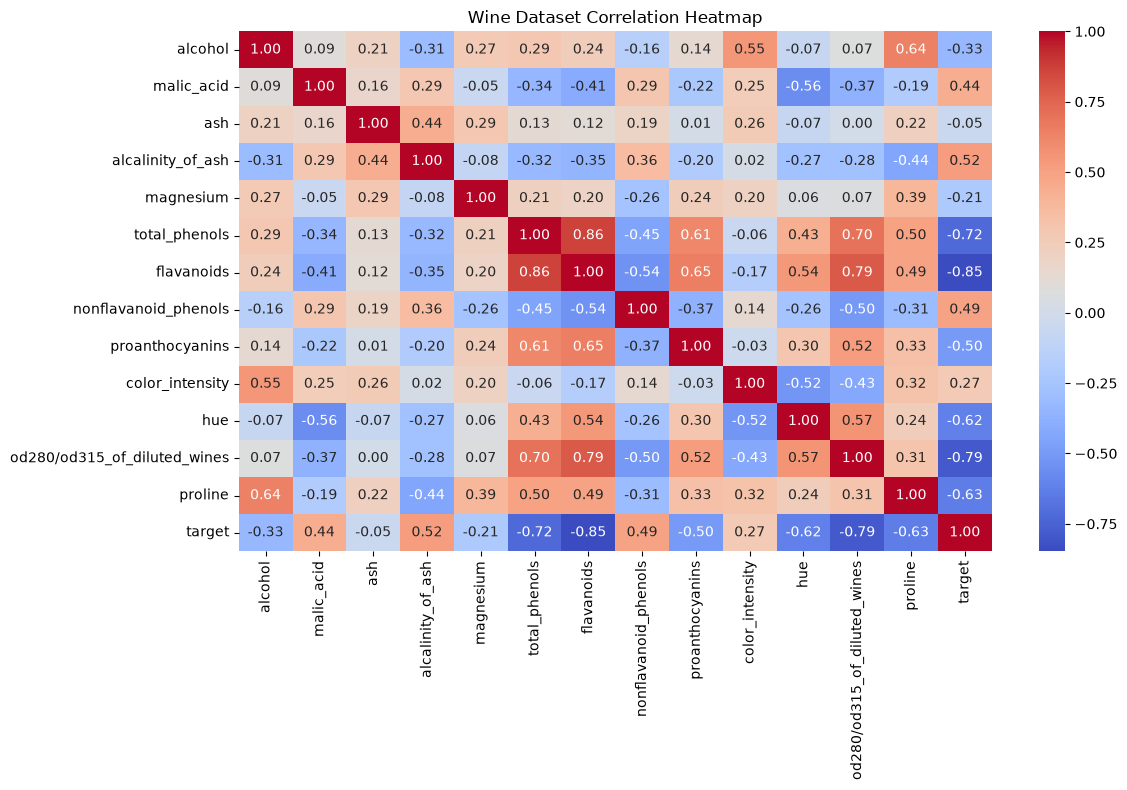

In [4]:
#Correlation heatap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Wine Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

Flavanoids have the strongest negative correlation of -0.85 with the target variable. This indicates that wines with higher flavanoid levels tend to belong to classes assigned lower numerical labels while Alcalinity of ash has the strongest positive correlation of +0.52 with the target meaning Wines with higher alcalinity of ash tend to have higher numerical class labels.

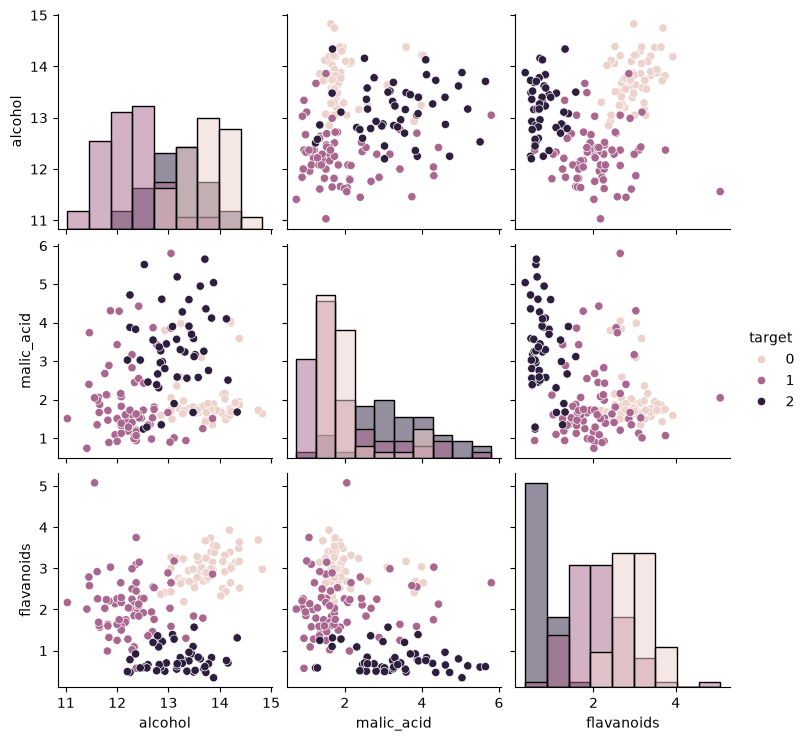

In [5]:
#pair plot
sns.pairplot(
    df[["alcohol", "malic_acid", "flavanoids", "target"]],
    hue="target",
    diag_kind="hist"
)

plt.show()

The pairplot shows the relationships between alcohol, malic acid, and flavanoids and the three wine classes (0, 1, and 2).
For alcohol distribution,Class 0 (light pink) has higher alcohol content, mostly between 13% and 14.5%
Class 1(purple) has lower alcohol content, between 11.5% and 13%.
Class 2 (black) overlaps with the other classes, making alcohol alone insufficient to distinguish all three groups

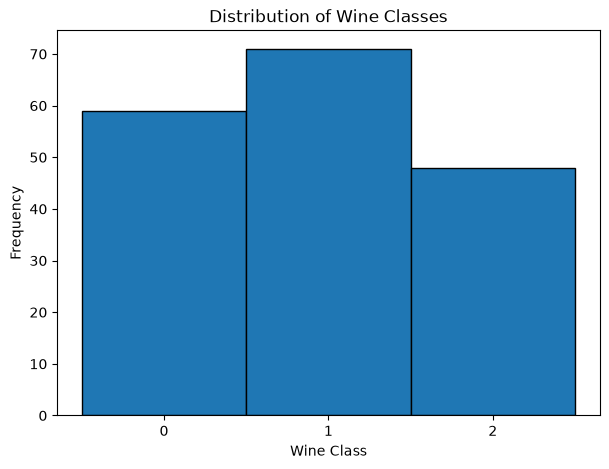

In [6]:
#Histogram of the target variable
plt.figure(figsize=(7, 5))

plt.hist(
    df["target"],
    bins=np.arange(-0.5, 3.5, 1),
    edgecolor="black"
)

plt.xticks([0, 1, 2])
plt.xlabel("Wine Class")
plt.ylabel("Frequency")
plt.title("Distribution of Wine Classes")
plt.show()

Class 1 has the highest frequency, with about 71 samples making it the most represented wine class.

In [7]:
#Apply feature scaling using StandardScaler
# Initialize scaler
scaler = StandardScaler()

# Fit on training data only
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

# Convert scaled features to DataFrame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

# Display first 5 rows
print(X_train_scaled_df.head())

      alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
36   0.385801   -0.637871  1.776668          -1.224532   0.696430   
30   0.948519   -0.765445  1.253174           0.853284   0.091785   
26   0.523354   -0.519409  0.954034          -1.046433  -0.445678   
12   0.973529   -0.555859  0.168793          -1.076116  -0.714409   
148  0.435820    0.820120  0.056615           0.556453  -0.512860   

     total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
36        0.526865    0.732292             -0.169549        -0.415783   
30        1.172795    1.333181             -0.590457         1.349742   
26        0.930572    1.006382             -0.169549        -0.260002   
12        0.526865    0.816627             -0.590457         0.363125   
148      -0.555068   -1.291756              0.756449        -0.606183   

     color_intensity       hue  od280/od315_of_diluted_wines   proline  
36         -0.167467  0.624378                      0.252908  0.467725  


The numerical features have been standardized to a common scale, with each feature having a mean of approximately zero and a standard deviation of one in the training set. Positive values indicate observations above the feature mean, while negative values indicate observations below the mean. For example, the alcohol value of 0.3858 indicates that the observation is approximately 0.39 standard deviations above the training mean, while the malic acid value of -0.6379 indicates approximately 0.64 standard deviations below the mean.

In [8]:
#Generate polynomial features
# Create polynomial features
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

# Transform scaled features
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

# Get polynomial feature names
poly_names = poly.get_feature_names_out(X.columns)

# Convert to DataFrame
X_train_poly_df = pd.DataFrame(
    X_train_poly,
    columns=poly_names,
    index=X_train.index
)

print("Original Shape:", X_train_scaled.shape)
print("Polynomial Shape:", X_train_poly.shape)

# Display first 5 rows
print(X_train_poly_df.head())

Original Shape: (142, 13)
Polynomial Shape: (142, 104)
      alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
36   0.385801   -0.637871  1.776668          -1.224532   0.696430   
30   0.948519   -0.765445  1.253174           0.853284   0.091785   
26   0.523354   -0.519409  0.954034          -1.046433  -0.445678   
12   0.973529   -0.555859  0.168793          -1.076116  -0.714409   
148  0.435820    0.820120  0.056615           0.556453  -0.512860   

     total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
36        0.526865    0.732292             -0.169549        -0.415783   
30        1.172795    1.333181             -0.590457         1.349742   
26        0.930572    1.006382             -0.169549        -0.260002   
12        0.526865    0.816627             -0.590457         0.363125   
148      -0.555068   -1.291756              0.756449        -0.606183   

     color_intensity  ...  color_intensity^2  color_intensity hue  \
36         -0.167467  

Note that the number of observations remains unchanged at 142, while the number of features increases from 13 to 104 because Polynomial features generates squared terms and interaction terms between the original features therefore increaing the feautures.

In [9]:
#Train a Linear Regression model
# Initialize Linear Regression
lr_model = LinearRegression()

# Train using polynomial features
lr_model.fit(X_train_poly, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test_poly)

# Calculate RMSE
rmse_lr = np.sqrt(
    mean_squared_error(y_test, y_pred_lr)
)

print("Linear Regression RMSE:", rmse_lr)

Linear Regression RMSE: 0.293607100715339


In [10]:
#Train a Lasso Regression model
# Initialize Lasso Regression
lasso_model = Lasso(
    alpha=0.1,
    max_iter=10000
)

# Train on polynomial features
lasso_model.fit(X_train_poly, y_train)

# Make predictions
y_pred_lasso = lasso_model.predict(X_test_poly)

# Calculate RMSE
rmse_lasso = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso)
)

print("Lasso Regression RMSE:", rmse_lasso)

Lasso Regression RMSE: 0.3557694921742665


In [11]:
#Compare Linear Regression and Lasso Regression
# Create comparison table
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Lasso Regression"
    ],
    "RMSE": [
        rmse_lr,
        rmse_lasso
    ]
})

print(results)

# Identify best model
best_model = results.loc[results["RMSE"].idxmin()]

print("\nBest Model:", best_model["Model"])
print("Lowest RMSE:", best_model["RMSE"])

               Model      RMSE
0  Linear Regression  0.293607
1   Lasso Regression  0.355769

Best Model: Linear Regression
Lowest RMSE: 0.293607100715339


RMSE with tehlowest values is an indocation that the model perform better. Therefore, the results show that Linear Regression performed better than Lasso Regression when predicting the numerically encoded wine classes using polynomial features.

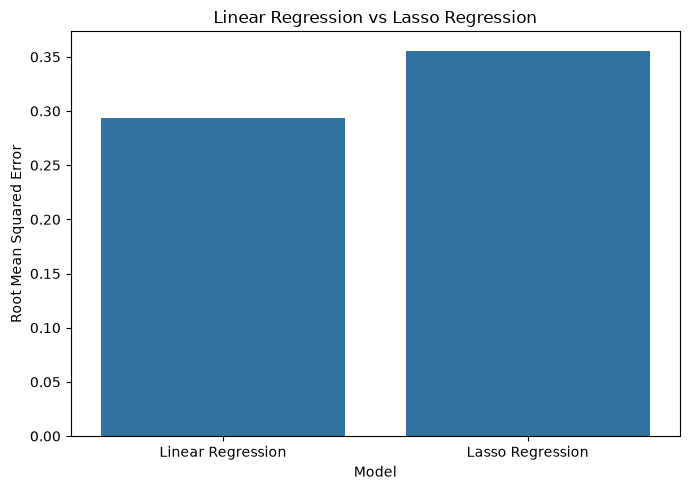

In [12]:
#Visualize model comparison
plt.figure(figsize=(7, 5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.title("Linear Regression vs Lasso Regression")
plt.ylabel("Root Mean Squared Error")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

In [13]:
#hyperparameter
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Pipeline for scaling, polynomial features, and Lasso
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("lasso", Lasso(max_iter=20000))
])

# Test different alpha values
param_grid = {
    "lasso__alpha": [0.001, 0.01, 0.1, 1, 10]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

# Fit using original training features
grid.fit(X_train, y_train)

# Evaluate on the test set
y_pred_tuned = grid.predict(X_test)

rmse_tuned = np.sqrt(
    mean_squared_error(y_test, y_pred_tuned)
)

print("Best Alpha:", grid.best_params_["lasso__alpha"])
print("Tuned Lasso RMSE:", rmse_tuned)

Best Alpha: 0.01
Tuned Lasso RMSE: 0.21008922153822246


After hyperparameter tuning, Lasso Regression achieved the best performance, outperforming both the original Lasso Regression and Linear Regression models with the lowest RMSE of 0.210089

Therefore Hyperparameter tuning is important as it significantly improved the performance of Lasso Regression on the Wine dataset. This is because model performance depends not only on the algorithm but also on the parameters used.